# 06 · BiLSTM Text Classifier (Module IV, CO4)

**Theory.** A recurrent network reads tokens one at a time and carries a hidden state forward. Plain
RNNs suffer from **vanishing gradients**: the error signal is multiplied by the same weights at every
time step, so it shrinks exponentially and early words stop influencing learning. An **LSTM** adds a
*cell state* with additive updates, controlled by three gates (sigmoid values between 0 and 1):
the *forget* gate decides what to erase from the cell, the *input* gate what new information to
write, and the *output* gate what to expose as the hidden state. The additive path lets gradients
flow across many steps. A **Bi**LSTM runs one LSTM left→right and another right→left and
concatenates their final states, so every word's context on both sides is used. Unlike averaged
embeddings (nb05), word order matters here.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import src.utils  # FIRST: cache folders

import time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
import gensim.downloader as api

from src.utils import FAST, SEED, get_device, set_seed
from src.data import AG_LABELS, load
from src.preprocess import clean
from src.evaluate import classification_metrics, plot_confusion, save_results

MAX_LEN, EMB_DIM, HIDDEN, BATCH, EPOCHS, LR = 64, 100, 128, 64, 3, 1e-3

## Data → integer sequences
Tokens: `clean(text, remove_stop=False, lemma=False)`. Stop words are **kept**, because the LSTM can
use word order and function words ("not", "after"). Vocabulary = training words seen ≥ 2 times;
index 0 = padding, 1 = unknown word. Sequences are cut or padded to 64 tokens.

In [2]:
train, val, test = load("ag_train"), load("ag_val"), load("ag_test")
tok = lambda texts: [clean(t, remove_stop=False, lemma=False).split() for t in texts]
train_tok, val_tok, test_tok = tok(train.text), tok(val.text), tok(test.text)

counts = Counter(w for doc in train_tok for w in doc)
itos = ["<pad>", "<unk>"] + sorted(w for w, c in counts.items() if c >= 2)
stoi = {w: i for i, w in enumerate(itos)}

def encode(docs):
    """List of token lists -> (LongTensor [n, MAX_LEN], lengths). Unknown words -> 1, padding -> 0."""
    X = torch.zeros(len(docs), MAX_LEN, dtype=torch.long)
    lengths = torch.zeros(len(docs), dtype=torch.long)
    for i, doc in enumerate(docs):
        ids = [stoi.get(w, 1) for w in doc][:MAX_LEN] or [1]  # empty doc -> one <unk>
        X[i, :len(ids)] = torch.tensor(ids)
        lengths[i] = len(ids)
    return X, lengths

data = {name: (*encode(d), torch.tensor(df.label.values))
        for name, d, df in [("train", train_tok, train), ("val", val_tok, val), ("test", test_tok, test)]}
lens = np.array([len(d) for d in train_tok])
print(f"vocab {len(itos):,} | tokens per doc: median {np.median(lens):.0f}, "
      f"{(lens > MAX_LEN).mean():.1%} longer than {MAX_LEN} (truncated)")

vocab 27,952 | tokens per doc: median 37, 1.6% longer than 64 (truncated)


## The model (about 20 lines)

In [3]:
class BiLSTM(nn.Module):
    def __init__(self, vocab_size, n_classes=4, emb_weights=None):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB_DIM, padding_idx=0)
        if emb_weights is not None:                      # optional GloVe start
            self.emb.weight.data.copy_(emb_weights)
        self.lstm = nn.LSTM(EMB_DIM, HIDDEN, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.out = nn.Linear(2 * HIDDEN, n_classes)

    def forward(self, x, lengths):
        # Packing tells the LSTM each sequence's true length, so it stops at the last real word
        # instead of reading padding (important for the backward direction).
        packed = pack_padded_sequence(self.emb(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                    # h: [2 directions, batch, HIDDEN]
        both = torch.cat([h[0], h[1]], dim=1)           # forward final state + backward final state
        return self.out(self.drop(both))                 # class scores (logits)

## Device: time both, use the faster
`get_device()` would pick Apple's MPS GPU. For a small LSTM with packed sequences, the CPU can be
faster, because MPS pays per-kernel launch overheads. So we measure instead of assuming.

In [4]:
def time_steps(device, n=10):
    set_seed(); m = BiLSTM(len(itos)).to(device); opt = torch.optim.Adam(m.parameters(), lr=LR)
    X, L, y = (t[:BATCH] for t in data["train"])
    X, y = X.to(device), y.to(device)
    for i in range(n + 3):
        if i == 3:
            start = time.perf_counter()
        loss = nn.functional.cross_entropy(m(X, L), y); opt.zero_grad(); loss.backward(); opt.step()
    if device.type == "mps":
        torch.mps.synchronize()
    return (time.perf_counter() - start) / n * 1000

candidates = {d: time_steps(torch.device(d)) for d in {"cpu", get_device().type}}
device = torch.device(min(candidates, key=candidates.get))
print({d: f"{ms:.0f} ms/step" for d, ms in candidates.items()}, "-> using", device)

{'mps': '88 ms/step', 'cpu': '52 ms/step'} -> using cpu


## Training loop

In [5]:
def batches(split, shuffle, gen=None):
    X, L, y = data[split]
    order = torch.randperm(len(y), generator=gen) if shuffle else torch.arange(len(y))
    for i in range(0, len(y), BATCH):
        idx = order[i:i + BATCH]
        yield X[idx].to(device), L[idx], y[idx].to(device)

@torch.no_grad()
def predict(model, split):
    model.eval()
    return torch.cat([model(X, L).argmax(1).cpu() for X, L, _ in batches(split, shuffle=False)]).numpy()

def train_model(emb_weights=None):
    set_seed(); gen = torch.Generator().manual_seed(SEED)
    model = BiLSTM(len(itos), emb_weights=emb_weights).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history, start = [], time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train(); total = 0.0
        for X, L, y in batches("train", shuffle=True, gen=gen):
            loss = nn.functional.cross_entropy(model(X, L), y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)  # guards against exploding gradients
            opt.step(); total += loss.item() * len(y)
        val_acc = (predict(model, "val") == data["val"][2].numpy()).mean()
        history.append({"epoch": epoch, "train_loss": total / len(data["train"][2]), "val_acc": val_acc})
        print(f"epoch {epoch}: train loss {history[-1]['train_loss']:.4f}  val acc {val_acc:.4f}")
    return model, pd.DataFrame(history), time.perf_counter() - start

## GloVe-initialised embeddings (the optional flag)
Rows for words in GloVe start from their GloVe vector; the rest keep PyTorch's random start.
All embeddings are still fine-tuned during training.

In [6]:
glove = api.load("glove-wiki-gigaword-100")
glove_weights = nn.Embedding(len(itos), EMB_DIM, padding_idx=0).weight.data.clone()
found = [i for i, w in enumerate(itos) if w in glove.key_to_index]
glove_weights[found] = torch.tensor(glove[[itos[i] for i in found]])
print(f"GloVe covers {len(found):,} of {len(itos):,} vocabulary words ({len(found) / len(itos):.1%})")

GloVe covers 26,360 of 27,952 vocabulary words (94.3%)


In [7]:
runs = {}
for name, weights in [("BiLSTM random init", None), ("BiLSTM GloVe init", glove_weights)]:
    print(f"--- {name}")
    model, hist, train_s = train_model(weights)
    t = time.perf_counter(); pred = predict(model, "test"); infer_s = time.perf_counter() - t
    runs[name] = dict(model=model, hist=hist, train_s=train_s, pred=pred,
                      infer_ms=infer_s / len(test) * 1000,
                      metrics=classification_metrics(test.label, pred, AG_LABELS))

n_params = sum(p.numel() for p in runs["BiLSTM GloVe init"]["model"].parameters())
table = pd.DataFrame([{"model": k, "accuracy": r["metrics"]["accuracy"], "macro_P": r["metrics"]["macro_precision"],
                       "macro_R": r["metrics"]["macro_recall"], "macro_F1": r["metrics"]["macro_f1"],
                       "train s": round(r["train_s"], 1), "infer ms/doc": round(r["infer_ms"], 3)}
                      for k, r in runs.items()]).set_index("model")
print(f"parameters: {n_params:,} ({n_params * 4 / 1e6:.1f} MB as float32); "
      f"{len(itos) * EMB_DIM / n_params:.0%} of them are the embedding table")
table

--- BiLSTM random init


epoch 1: train loss 0.7676  val acc 0.8260


epoch 2: train loss 0.3737  val acc 0.8505


epoch 3: train loss 0.2548  val acc 0.8535


--- BiLSTM GloVe init


epoch 1: train loss 0.4082  val acc 0.8905


epoch 2: train loss 0.2561  val acc 0.9045


epoch 3: train loss 0.1961  val acc 0.9075


parameters: 3,031,748 (12.1 MB as float32); 92% of them are the embedding table


,accuracy,macro_P,macro_R,macro_F1,train s,infer ms/doc
model,,,,,,
BiLSTM random init,0.8626,0.8675,0.8626,0.8626,89.5,0.183
BiLSTM GloVe init,0.9066,0.9079,0.9066,0.9067,80.2,0.185


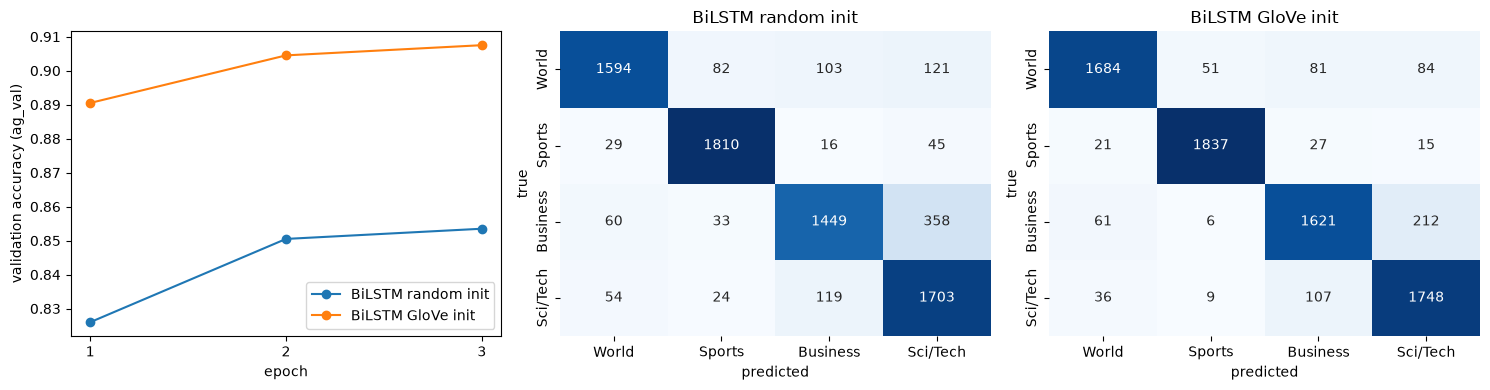

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, r in runs.items():
    axes[0].plot(r["hist"].epoch, r["hist"].val_acc, "o-", label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation accuracy (ag_val)"); axes[0].legend()
axes[0].set_xticks(range(1, EPOCHS + 1))
for ax, name in zip(axes[1:], runs):
    plot_confusion(test.label, runs[name]["pred"], AG_LABELS, ax=ax, title=name)
plt.tight_layout(); plt.show()

The validation curve shows whether GloVe gives a head start in epoch 1. It starts from vectors that
already encode meaning, while random embeddings must learn everything from 30k headlines.

In [9]:
r = runs["BiLSTM GloVe init"]  # main configuration, fixed in advance
save_results("bilstm", {
    "dataset": "ag_news", "n_train": len(train), "n_test": len(test), "config": "BiLSTM GloVe init",
    "device": str(device), "hyperparams": dict(max_len=MAX_LEN, emb_dim=EMB_DIM, hidden=HIDDEN,
                                               batch=BATCH, epochs=EPOCHS, lr=LR),
    "metrics": r["metrics"], "train_time_s": round(r["train_s"], 1),
    "infer_ms_per_doc": round(r["infer_ms"], 3), "model_size_mb": round(n_params * 4 / 1e6, 1),
    "n_params": n_params, "val_history": {k: v["hist"].to_dict("records") for k, v in runs.items()},
    "variants": table.reset_index().to_dict("records"), "y_pred": r["pred"],
})

saved results/bilstm.json


PosixPath('/Users/mihirmandavia/nlp-news/results/bilstm.json')

## Viva notes
**Q1. What do the three LSTM gates do?**
Forget gate f = σ(W_f[h, x] + b): what to keep from the old cell state. Input gate i: how much of
the new candidate g = tanh(W_g[h, x] + b) to write. Output gate o: how much of tanh(cell) becomes
the hidden state. Cell update: c_t = f ⊙ c_{t-1} + i ⊙ g, and h_t = o ⊙ tanh(c_t).

**Q2. Why do LSTMs reduce vanishing gradients?**
In a plain RNN the gradient is multiplied by the recurrent weight matrix at every step, so it shrinks
(or explodes) exponentially. The LSTM cell update is *additive* (c_t = f·c_{t−1} + …), so when the
forget gate is near 1 the gradient passes almost unchanged. Gradient clipping (norm 5) handles the
exploding case.

**Q3. Why pack the padded sequences?**
Without packing, the forward LSTM would read padding zeros after the text, and the backward LSTM would
start from padding. Packing makes each direction stop at the real sequence length.